# Уравнение Пуассона. Метод сопряжённых градиентов

In [129]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse.linalg import LinearOperator, cg
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

In [130]:
def make_grid(x_min, x_max, y_min, y_max, nx, ny):
    hx = (x_max - x_min) / nx
    hy = (y_max - y_min) / ny

    x = x_min + (np.arange(nx) + 0.5) * hx
    y = y_min + (np.arange(ny) + 0.5) * hy

    X, Y = np.meshgrid(x, y, indexing='ij')
    return X, Y, hx, hy

In [131]:
def convergence_order(errors, hs):
    errors = np.asarray(errors, dtype=float)
    hs = np.asarray(hs, dtype=float)
    return np.log(errors[:-1] / errors[1:]) / np.log(hs[:-1] / hs[1:])

In [132]:
def OpL(u, hx, hy, alpha):
    Lu = np.zeros_like(u)

    Lu[1:-1, :] += (2*u[1:-1, :] - u[:-2, :] - u[2:, :]) / hx**2
    Lu[0,  :]   += (u[0, :]  - u[1, :])  / hx**2
    Lu[-1, :]   += (u[-1, :] - u[-2, :]) / hx**2

    Lu[:, 1:-1] += (2*u[:, 1:-1] - u[:, :-2] - u[:, 2:]) / hy**2
    Lu[:, 0]    += (u[:, 0]  - u[:, 1])  / hy**2
    Lu[:, -1]   += (u[:, -1] - u[:, -2]) / hy**2

    Lu += alpha * u

    return Lu

In [133]:
def optimal_tau(hx, hy, alpha):
    lam_min = alpha
    lam_max = alpha + 4.0/hx**2 + 4.0/hy**2
    return 2.0 / (lam_min + lam_max), lam_min, lam_max

In [134]:
def simple_iteration(OpL, F, tau, tol=1e-8, max_iter=200000):
    u = np.zeros_like(F)
    r = OpL(u) - F
    if np.max(np.abs(r)) < tol:
        return

    for k in range(1, max_iter + 1):
        u -= tau * r
        r = OpL(u) - F
        residual = np.max(np.abs(r))
        yield k, u, r, residual
        if residual < tol:
            return

In [135]:
def solve_simple_iteration(OpL, F, X, Y, hx, hy, alpha,
                           u_ex=None, tol=1e-8, max_iter=200000):
    tau, _, _ = optimal_tau(hx, hy, alpha)
    u = np.zeros_like(F)
    residuals = [np.max(np.abs(OpL(u) - F))]
    errors = [np.max(np.abs(u - u_ex))] if u_ex is not None else []
    last_k = 0

    for k, u, r, residual in simple_iteration(OpL, F, tau, tol, max_iter):
        last_k = k
        residuals.append(residual)
        if u_ex is not None:
            errors.append(np.max(np.abs(u - u_ex)))

    if residuals[-1] >= tol:
        raise RuntimeError("Простая итерация: заданный допуск не достигнут")

    out = dict(X=X, Y=Y, hx=hx, hy=hy, u=u, F=F, h=max(hx, hy),
               iters=last_k, residuals=np.array(residuals),
               errors_inf=np.array(errors))
    if u_ex is not None:
        err = np.abs(u - u_ex)
        out.update(u_ex=u_ex, err=err, err_max=err.max(),
                   err_L2=np.sqrt(hx * hy * np.sum(err**2)))
    return out

# Задача 2.15 (пункт а)

## Постановка

Решить задачу Неймана для экранированного уравнения Пуассона
в прямоугольнике:

$$
\begin{cases}
\Delta u - 4u = 12(1 - 2y^2), & -1 < x < 1, \quad -1 < y < 1, \\[4pt]
u_x(-1, y) = 2\sinh 2, & u_x(1, y) = -2\sinh 2, \\[4pt]
u_y(x, -1) = 2\cosh 2 - 12, & u_y(x, 1) = 2\cosh 2 + 12.
\end{cases}
$$

## Точное решение:

$$
u_0(x, y) = -\cosh(2x) + \sinh(2y) + 6y^2.
$$


In [136]:
def RHS_a(X, Y, hx, hy):
    F = (24.0 * Y**2 - 12.0).astype(float)

    F[0,  :] += -2.0 * np.sinh(2.0) / hx
    F[-1, :] += -2.0 * np.sinh(2.0) / hx
    F[:, 0]  += -(2.0 * np.cosh(2.0) - 12.0) / hy
    F[:, -1] +=  (2.0 * np.cosh(2.0) + 12.0) / hy
    return F

In [137]:
def exact_solution(X, Y):
    return -np.cosh(2.0*X) + np.sinh(2.0*Y) + 6.0*Y**2

In [138]:
def solve_a_simple_iteration(nx, ny=None, tol=1e-8, max_iter=200000):
    ny = nx if ny is None else ny
    X, Y, hx, hy = make_grid(-1.0, 1.0, -1.0, 1.0, nx, ny)
    alpha = 4.0
    opL = lambda u: OpL(u, hx, hy, alpha)
    F = RHS_a(X, Y, hx, hy)
    u_ex = exact_solution(X, Y)
    return solve_simple_iteration(opL, F, X, Y, hx, hy, alpha,
                                  u_ex=u_ex, tol=tol, max_iter=max_iter)

# Задача 2.15 (пункт б)

## Постановка

Прямоугольный пружинный матрас, пружины распределены равномерно
с жёсткостью $k$, полотно имеет натяжение $T$. На матрас кладут
тонкое тяжёлое кольцо массы $M$ радиуса $R$ с центром в точке
$(x_0, y_0)$. Найти прогиб матраса $u(x, y)$:

$$
\begin{cases}
-T\,\Delta u + k\,u = f(x, y), & 0 < x < L_x, \quad 0 < y < L_y, \\[4pt]
u_x(0, y) = 0, & u_x(L_x, y) = 0, \\[4pt]
u_y(x, 0) = 0, & u_y(x, L_y) = 0,
\end{cases}
$$

где нагрузка от кольца:

$$
f(x, y) = \frac{Mg}{2\pi R}\,\delta\!\left(\rho - R\right),
\qquad
\rho = \sqrt{(x - x_0)^2 + (y - y_0)^2}.
$$

## Регуляризация дельта-функции:

$$
f_\sigma(x, y) = C_\sigma \exp\!\left(-\frac{(\rho - R)^2}{2\sigma^2}\right),
\qquad
C_\sigma = \frac{Mg}{\displaystyle\iint_\Omega
   \exp\!\left(-\frac{(\rho - R)^2}{2\sigma^2}\right) dS}.
$$

In [139]:
def RHS_b(X, Y, hx, hy, M=1.0, R=0.3,
          x0=None, y0=None, sigma=0.05,
          g=9.81, T=1.0):
    if x0 is None:
        x0 = 0.5 * (X.min() + X.max())
    if y0 is None:
        y0 = 0.5 * (Y.min() + Y.max())

    rho    = np.sqrt((X - x0)**2 + (Y - y0)**2)
    kernel = np.exp(-(rho - R)**2 / (2.0 * sigma**2))

    total = M * g / T
    norm = hx * hy * np.sum(kernel)
    F     = total * kernel / norm
    return F

In [140]:
def solve_b_simple_iteration(nx, ny,
                             M=1.0, R=0.3, x0=None, y0=None,
                             sigma=None, g=9.81, T=1.0, k=4.0,
                             Lx=2.0, Ly=1.0, tol=1e-8, max_iter=200000):
    X, Y, hx, hy = make_grid(0.0, Lx, 0.0, Ly, nx, ny)
    if sigma is None:
        sigma = 2.0 * max(hx, hy)
    alpha = k / T
    opL = lambda u: OpL(u, hx, hy, alpha)
    F = RHS_b(X, Y, hx, hy, M=M, R=R, x0=x0, y0=y0,
              sigma=sigma, g=g, T=T)
    return solve_simple_iteration(opL, F, X, Y, hx, hy, alpha,
                                  tol=tol, max_iter=max_iter)

# Метод сопряжённых градиентов

Метод сопряжённых градиентов применим к системе $Au=F$, если оператор $A$ симметричен и положительно определён.

В обеих задачах после переноса членов и деления на $T$ в пункте б получаем
$$
A=-\Delta_h+\alpha I,
\qquad
\alpha=4 \text{ в пункте а},\qquad \alpha=\frac{k}{T}>0 \text{ в пункте б}.
$$
Граничные потоки Неймана включены в правую часть $F$. Поэтому в операторе остаётся разностный лапласиан с однородными условиями Неймана.

Симметричность следует из разностной схемы: коэффициенты, связывающие любые два соседних узла, одинаковы в обоих направлениях. По оси $x$ это $-1/h_x^2$, по оси $y$ — $-1/h_y^2$. Добавление диагонального слагаемого $\alpha I$ симметричность сохраняет.

Для любого вещественного сеточного вектора $v$:
$$
(v,Av)=
\frac{1}{h_x^2}\sum_{i=0}^{n_x-2}\sum_{j=0}^{n_y-1}
(v_{i+1,j}-v_{i,j})^2
+
\frac{1}{h_y^2}\sum_{i=0}^{n_x-1}\sum_{j=0}^{n_y-2}
(v_{i,j+1}-v_{i,j})^2
+
\alpha\sum_{i=0}^{n_x-1}\sum_{j=0}^{n_y-1}v_{i,j}^2.
$$
Первые два слагаемых неотрицательны, а последнее при $\alpha>0$ строго положительно для $v\ne0$. Следовательно, $(v,Av)>0$: оператор положительно определён.

Сам лапласиан с условиями Неймана имеет нулевое собственное значение, соответствующее постоянному вектору. Слагаемое $\alpha I$ сдвигает все собственные значения на $\alpha>0$ и устраняет эту вырожденность. Таким образом, в обоих пунктах выполнены условия применимости метода сопряжённых градиентов.

In [141]:
class StopCG(Exception):
    def __init__(self, u):
        self.u = u.copy()

    @staticmethod
    def callback(v, A, b, shape, u_ex, tol, residuals, errors, snapshots):
        residual = np.max(np.abs(A @ v - b))
        residuals.append(residual)
        if snapshots is not None:
            snapshots.append(v.reshape(shape).copy())
        if u_ex is not None:
            errors.append(np.max(np.abs(v.reshape(shape) - u_ex)))
        if residual < tol:
            raise StopCG(v)

In [142]:
def solve_conjugate_gradients(OpL, F, X, Y, hx, hy,
                              u_ex=None, tol=1e-8, max_iter=200000,
                              save_snapshots=False):
    if tol <= 0 or max_iter < 1:
        raise ValueError("Нужны tol > 0 и max_iter >= 1")
    shape = F.shape

    A = LinearOperator((F.size, F.size),
                       matvec=lambda v: OpL(v.reshape(shape)).ravel(),
                       dtype=float)
    b = F.ravel()
    u = np.zeros_like(b)
    residuals = [np.max(np.abs(A @ u - b))]
    errors = [np.max(np.abs(u.reshape(shape) - u_ex))] if u_ex is not None else []
    snapshots = [u.reshape(shape).copy()] if save_snapshots else None
    callback = lambda v: StopCG.callback(
        v, A, b, shape, u_ex, tol, residuals, errors, snapshots
    )

    if residuals[0] >= tol:
        try:
            u, info = cg(A, b, x0=u, rtol=0, atol=0,
                         maxiter=max_iter, callback=callback)
        except StopCG as stop:
            u = stop.u

    residual = np.max(np.abs(A @ u - b))
    if not np.isfinite(residual) or residual >= tol:
        raise RuntimeError(f"CG: невязка {residual:.3e}, допуск {tol:.3e}")

    u = u.reshape(shape)
    out = dict(X=X, Y=Y, hx=hx, hy=hy, u=u, F=F, h=max(hx, hy),
               iters=len(residuals)-1, residuals=np.array(residuals),
               errors_inf=np.array(errors), snapshots=snapshots)
    if u_ex is not None:
        err = np.abs(u - u_ex)
        out.update(u_ex=u_ex, err=err, err_max=err.max(),
                   err_L2=np.sqrt(hx * hy * np.sum(err**2)))
    return out

In [143]:
def solve_a_conjugate_gradients(nx, ny=None, tol=1e-8, max_iter=200000,
                                save_snapshots=False):
    ny = nx if ny is None else ny
    X, Y, hx, hy = make_grid(-1, 1, -1, 1, nx, ny)
    opL = lambda u: OpL(u, hx, hy, 4.0)
    F = RHS_a(X, Y, hx, hy)
    return solve_conjugate_gradients(opL, F, X, Y, hx, hy,
                                     u_ex=exact_solution(X, Y),
                                     tol=tol, max_iter=max_iter, save_snapshots=save_snapshots)

In [144]:
def solve_b_conjugate_gradients(nx, ny,
                             M=1.0, R=0.3, x0=None, y0=None,
                             sigma=None, g=9.81, T=1.0, k=4.0,
                             Lx=2.0, Ly=1.0, tol=1e-8, max_iter=200000,
                             save_snapshots=False):
    X, Y, hx, hy = make_grid(0.0, Lx, 0.0, Ly, nx, ny)
    if sigma is None:
        sigma = 2.0 * max(hx, hy)
    alpha = k / T
    opL = lambda u: OpL(u, hx, hy, alpha)
    F = RHS_b(X, Y, hx, hy, M=M, R=R, x0=x0, y0=y0,
              sigma=sigma, g=g, T=T)
    return solve_conjugate_gradients(opL, F, X, Y, hx, hy,
                                  tol=tol, max_iter=max_iter, save_snapshots=save_snapshots)

## Визуализация

In [145]:
def plot_convergence_order(errors, hs):
    errors = np.asarray(errors, dtype=float)
    hs = np.asarray(hs, dtype=float)

    fig, ax = plt.subplots(figsize=(6, 5), dpi=80)

    ax.loglog(hs, errors, 'o-', color='black',
              linewidth=1.5, markersize=6, label="Численная погрешность")

    h_ref = np.array([hs.min(), hs.max()])
    for p in (1, 2):
        ref = errors[0] * (h_ref / hs[0])**p
        ax.loglog(h_ref, ref, '--', linewidth=1.0,
                  label=f"$O(h^{p})$")

    ax.set_xlabel("Шаг сетки $h$")
    ax.set_ylabel("Погрешность")
    ax.set_title("Порядок аппроксимации")
    ax.grid(True, which='both', linestyle=':', alpha=0.6)
    ax.legend()
    plt.tight_layout()
    plt.show()

In [146]:
def plot_solution(res, title="", flip=False):
    if "u_ex" in res:
        fields = [(res["u_ex"], "Точное решение"),
                  (res["u"], "Численное решение"),
                  (res["err"], "Погрешность")]
    else:
        fields = [(-res["u"] if flip else res["u"], "Прогиб матраса")]
    fig = plt.figure(figsize=(5 * len(fields), 4), dpi=80)
    for i, (u, label) in enumerate(fields, start=1):
        ax = fig.add_subplot(1, len(fields), i, projection="3d")
        ax.plot_surface(res["X"], res["Y"], u, cmap="RdBu_r")
        ax.set_title(label)
        ax.set_xlabel("x")
        ax.set_ylabel("y")
        ax.set_zlabel("u")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

In [147]:
def plot_iterations(results, tol, title=""):
    has_exact = all(len(res["errors_inf"]) > 0 for res in results.values())
    fig, axes = plt.subplots(1, 2 if has_exact else 1,
                             figsize=(12 if has_exact else 6, 4), dpi=80,
                             squeeze=False)
    ax = axes[0, 0]
    for method, res in results.items():
        ax.semilogy(res["residuals"], label=method)
    ax.axhline(tol, color="gray", ls="--", label="Допуск")
    ax.set_ylabel(r"$\|Au_k-F\|_\mathrm{inf}$")
    ax.set_title("Невязка")
    if has_exact:
        ax = axes[0, 1]
        for method, res in results.items():
            ax.semilogy(res["errors_inf"], label=method)
        ax.set_ylabel(r"$\|u_k-u_0\|_\mathrm{inf}$")
        ax.set_title("Погрешность")
    for ax in axes.ravel():
        ax.set_xlabel("Номер итерации")
        ax.grid(True, which="both", ls=":", alpha=0.5)
        ax.legend()
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

In [148]:
def plot_difference(res_cg, res_simple):
    difference = res_cg["u"] - res_simple["u"]
    fig, ax = plt.subplots(figsize=(6, 4), dpi=80)
    cf = ax.contourf(res_cg["X"], res_cg["Y"], difference,
                     levels=30, cmap="RdBu_r")
    fig.colorbar(cf, ax=ax)
    ax.set_aspect("equal")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_title("Разность решений: CG − простая итерация")
    plt.tight_layout()
    plt.show()

In [149]:
def plot_mattress(res, z_scale=1000.0, elev=25, azim=-60, title=""):
    X, Y = res["X"], res["Y"]
    u = -res["u"] * z_scale
    limit = max(np.max(np.abs(u)), 1e-12)

    fig = plt.figure(figsize=(8, 5), dpi=90)
    ax = fig.add_subplot(projection="3d")
    ax.plot_surface(X, Y, np.zeros_like(u), color="lightgray", alpha=0.2)
    surf = ax.plot_surface(X, Y, u, cmap="RdBu_r", edgecolor="none",
                           rstride=1, cstride=1)
    fig.colorbar(surf, ax=ax, shrink=0.6, label="Прогиб, мм")
    ax.set_zlim(-1.1 * limit, 0.1 * limit)
    ax.set_box_aspect((np.ptp(X), np.ptp(Y), 0.7))
    ax.view_init(elev=elev, azim=azim)
    ax.set_xlabel("x, м")
    ax.set_ylabel("y, м")
    ax.set_zlabel("Прогиб, мм")
    ax.set_title(title or "Прогиб матраса")
    plt.tight_layout()
    plt.show()

In [150]:
def plot_mattress_section(res, params):
    y0 = params.get("y0", params["Ly"]/2)
    j = np.argmin(np.abs(res["Y"][0, :] - y0))
    fig, ax = plt.subplots(figsize=(7, 3), dpi=90)
    ax.plot(res["X"][:, j], -1000 * res["u"][:, j])
    ax.axhline(0, color="gray", ls="--", label="Без нагрузки")
    ax.set_xlabel("x, м")
    ax.set_ylabel("Перемещение, мм")
    ax.set_title(f"Сечение при y={res['Y'][0, j]:.3f} м")
    ax.grid(True, ls=":", alpha=0.5)
    ax.legend()
    plt.tight_layout()
    plt.show()

In [151]:
def animate_cg(res, title="", flip=False, z_scale=1.0, interval=100):
    frames = res["snapshots"]
    if frames is None:
        raise ValueError("Решите задачу с save_snapshots=True")
    X, Y = res["X"], res["Y"]
    sign = -1 if flip else 1
    surfaces = [sign * z_scale * u for u in frames]
    low = min(u.min() for u in surfaces)
    high = max(u.max() for u in surfaces)
    if "u_ex" in res:
        low = min(low, res["u_ex"].min())
        high = max(high, res["u_ex"].max())
    pad = 0.08 * max(high - low, 1e-12)
    fig = plt.figure(figsize=(8, 5), dpi=90)
    ax = fig.add_subplot(projection="3d")

    def update(i):
        ax.clear()
        u = surfaces[i]
        if flip:
            ax.plot_surface(X, Y, np.zeros_like(u),
                            color="lightgray", alpha=0.2,
                            rstride=5, cstride=5)
        ax.plot_surface(X, Y, u, cmap="RdBu_r", edgecolor="none",
                        rstride=1, cstride=1, vmin=low, vmax=high)
        if "u_ex" in res:
            ax.plot_wireframe(X[::4, ::4], Y[::4, ::4], res["u_ex"][::4, ::4],
                              color="black", linewidth=0.4, alpha=0.4)
        ax.set_zlim(low - pad, high + pad)
        ax.set_box_aspect((np.ptp(X), np.ptp(Y), 0.7 if flip else 1.5))
        ax.view_init(elev=25, azim=-60)
        ax.set_xlabel("x, м" if flip else "x")
        ax.set_ylabel("y, м" if flip else "y")
        ax.set_zlabel("Прогиб, мм" if flip else "u")
        ax.set_title(f"{title}, итерация {i}")
        return []

    animation = FuncAnimation(fig, update, frames=len(surfaces),
                               interval=interval, blit=False, repeat=False)
    plt.close(fig)
    with plt.rc_context({"animation.writer": "ffmpeg", "animation.bitrate": 500}):
        return HTML(animation.to_html5_video())

## Пункт а: сравнение методов

In [152]:
tol = 1e-8
comparison_a = {
    "cg": solve_a_conjugate_gradients(40, tol=tol, save_snapshots=True),
    "simple": solve_a_simple_iteration(40, tol=tol),
}
print(f"{'Метод':<10} {'Итерации':>10} {'Невязка':>13} {'Ошибка Linf':>13} {'Ошибка L2':>13}")
for method, res in comparison_a.items():
    print(f"{method:<10} {res['iters']:10d} {res['residuals'][-1]:13.4e} "
          f"{res['err_max']:13.4e} {res['err_L2']:13.4e}")

Метод        Итерации       Невязка   Ошибка Linf     Ошибка L2
cg                 59    1.9794e-09    1.1740e-03    1.6027e-03
simple           7258    9.9941e-09    1.1741e-03    1.6027e-03


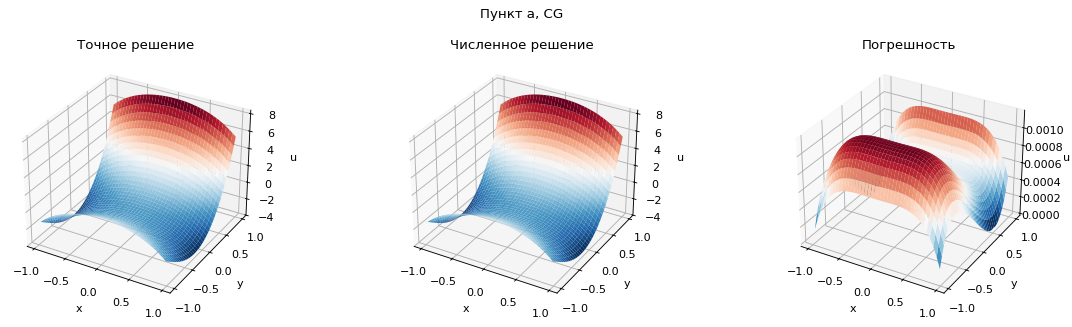

In [153]:
plot_solution(comparison_a["cg"], title="Пункт а, CG")

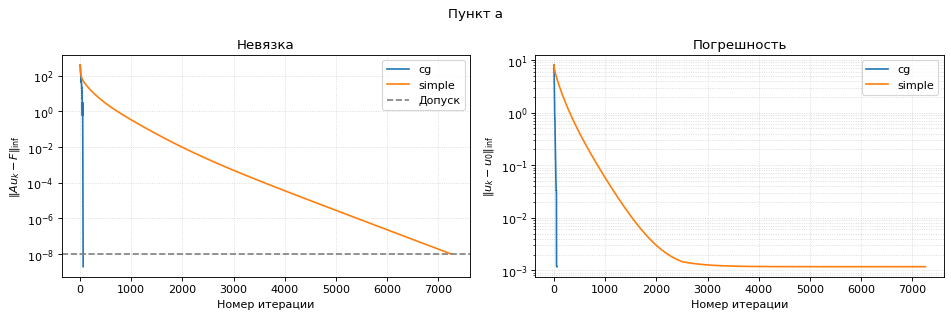

In [154]:
plot_iterations(comparison_a, tol, title="Пункт а")

In [155]:
animate_cg(comparison_a["cg"], title="Пункт а")

## Порядок точности

In [156]:
grids = [10, 20, 40, 80]
refinement = [solve_a_conjugate_gradients(n, tol=1e-9) for n in grids]
hs = np.array([r["h"] for r in refinement])
errs_L2 = np.array([r["err_L2"] for r in refinement])
errs_max = np.array([r["err_max"] for r in refinement])
p_L2 = convergence_order(errs_L2, hs)
p_max = convergence_order(errs_max, hs)
print(f"{'n':>5} {'h':>9} {'||e||L2':>13} {'p(L2)':>9} {'||e||inf':>13} {'p(max)':>9} {'CG ит.':>8}")
for i, (n, r) in enumerate(zip(grids, refinement)):
    p2 = f"{p_L2[i-1]:.4f}" if i else "—"
    pm = f"{p_max[i-1]:.4f}" if i else "—"
    print(f"{n:5d} {r['h']:9.4f} {r['err_L2']:13.5e} {p2:>9} "
          f"{r['err_max']:13.5e} {pm:>9} {r['iters']:8d}")

    n         h       ||e||L2     p(L2)      ||e||inf    p(max)   CG ит.
   10    0.2000   2.53745e-02         —   1.84164e-02         —       10
   20    0.1000   6.39669e-03    1.9880   4.68166e-03    1.9759       27
   40    0.0500   1.60273e-03    1.9968   1.17405e-03    1.9955       60
   80    0.0250   4.00909e-04    1.9992   2.93697e-04    1.9991      124


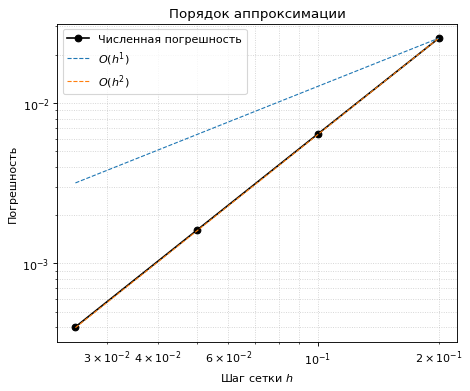

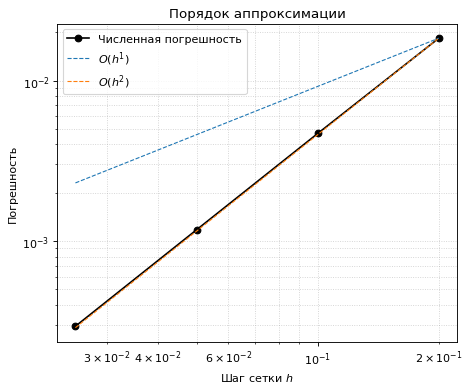

In [157]:
plot_convergence_order(errs_L2, hs)
plot_convergence_order(errs_max, hs)

## Пункт б: прогиб матраса

In [158]:
params_b = dict(nx=80, ny=40, M=10.0, R=0.15,
                T=1000.0, k=37500.0, Lx=2.0, Ly=1.0, sigma=0.04)
comparison_b = {
    "cg": solve_b_conjugate_gradients(**params_b, tol=tol, save_snapshots=True),
    "simple": solve_b_simple_iteration(**params_b, tol=tol),
}
print(f"{'Метод':<10} {'Итерации':>10} {'Невязка':>13} {'Макс. прогиб, мм':>17}")
for method, res in comparison_b.items():
    print(f"{method:<10} {res['iters']:10d} {res['residuals'][-1]:13.4e} "
          f"{1000 * np.max(np.abs(res['u'])):17.4f}")
difference = np.max(np.abs(comparison_b["cg"]["u"] - comparison_b["simple"]["u"]))
print(f"Максимальная разность решений: {difference:.3e}")
res_b = comparison_b["cg"]
area = res_b["hx"] * res_b["hy"]
print(f"Интеграл нагрузки: {params_b['T'] * area * np.sum(res_b['F']):.8f}")
print(f"Вес кольца:        {params_b['M'] * 9.81:.8f}")
print(f"Сила пружин:       {params_b['k'] * area * np.sum(res_b['u']):.8f}")
print(f"Средний прогиб:     {1000 * np.mean(res_b['u']):.4f} мм")

Метод        Итерации       Невязка  Макс. прогиб, мм
cg                122    7.2376e-09            7.8745
simple           2643    9.9581e-09            7.8745
Максимальная разность решений: 2.686e-10
Интеграл нагрузки: 98.10000000
Вес кольца:        98.10000000
Сила пружин:       98.10000000
Средний прогиб:     1.3080 мм


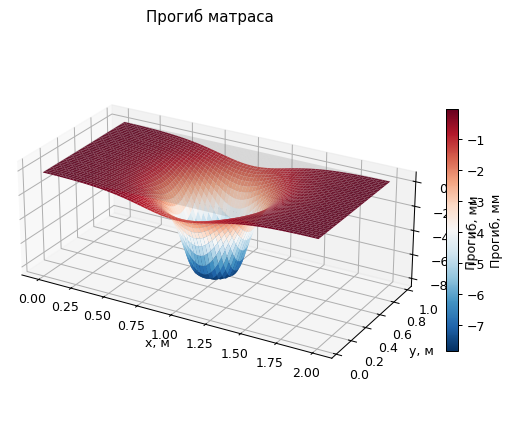

In [159]:
plot_mattress(comparison_b["cg"])

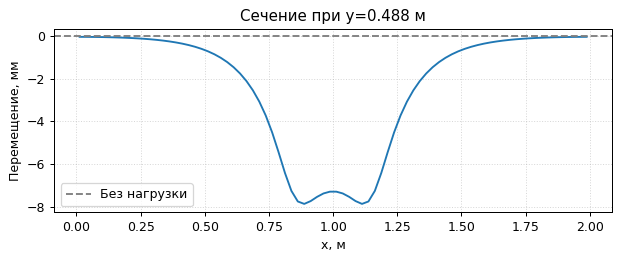

In [160]:
plot_mattress_section(comparison_b["cg"], params_b)

In [161]:
animate_cg(comparison_b["cg"], title="Матрас", flip=True, z_scale=1000)

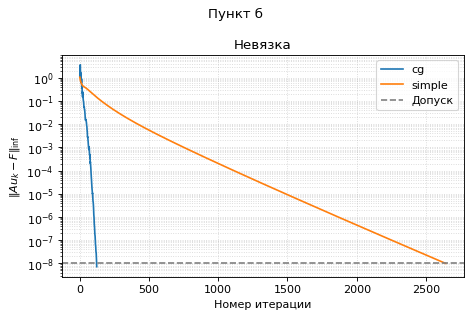

In [ ]:
plot_iterations(comparison_b, tol, title="Пункт б")

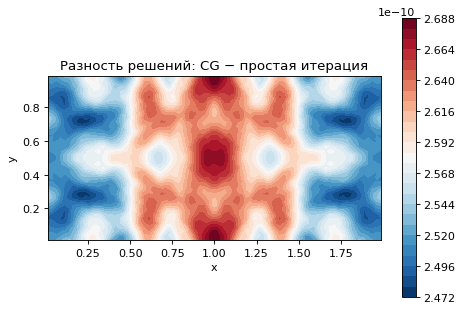

In [162]:
plot_difference(comparison_b["cg"], comparison_b["simple"])